## Exercise 1: X, y, split, and a baseline.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

In [2]:
# Cell 2: Features (X) and target (y)

df = pd.read_csv("../02_data/data/titanic.csv")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[features]
y = df["survived"]
print("X:", X.shape)
print("y:", y.shape)
display(X.head(3))

X: (891, 7)
y: (891,)


,pclass,sex,age,sibsp,parch,fare,embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S


In [3]:
# Cell 3: Split into training and test sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Survival rate - train: {y_train.mean():.1%}, test: {y_test.mean():.1%}")
print("First 5 training rows:", X_train.index[:5].tolist())

Train: (712, 7)  Test: (179, 7)
Survival rate - train: 38.3%, test: 38.5%
First 5 training rows: [692, 481, 527, 855, 801]


In [4]:
# Cell 4: What stratify protects you from

_, _, _, y_test_random = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Without stratify, test survival rate: {y_test_random.mean():.1%}")


Without stratify, test survival rate: 41.3%


In [5]:
# Cell 5: A baseline to beat

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Predictions for 5 test passengers:", baseline.predict(X_test.head()))
print(f"Baseline accuracy on the test set: {baseline.score(X_test, y_test):.1%}")

Predictions for 5 test passengers: [0 0 0 0 0]
Baseline accuracy on the test set: 61.5%


## Exercise 1 answers
- **X** = 7 features (`pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`); **y** = `survived`.
- **Left out:** `alive` (it is the answer: leakage), `class` and `embark_town` (copies), `who`, `adult_male` and `alone` (calculated from other features), `deck` (77% missing).
- **Split:** 712 training rows and 179 test rows (80/20). `stratify=y` keeps the survival rate equal: 38.3% vs 38.5%. Without it, the test set gets 41.3%.
- **Baseline:** always predicting "died" scores **61.5%**, so a real model must beat that to have learned anything.


## Exercise 2: Logistic regression

In [6]:
# Cell 1: A table of complete number columns

def simple_features(X):
    """Only the complete number columns, plus sex as 1/0."""
    table = X[["pclass", "sibsp", "parch", "fare"]].copy()
    table["is_male"] = (X["sex"] == "male").astype(int)
    return table


X_train_simple = simple_features(X_train)
X_test_simple = simple_features(X_test)
display(X_train_simple.head(3))

,pclass,sibsp,parch,fare,is_male
692,3,0,0,56.4958,1
481,2,0,0,0.0000,1
527,1,0,0,221.7792,1


In [7]:
# Cell 2: Train and score

model = LogisticRegression()
model.fit(X_train_simple, y_train)
print(f"Train accuracy: {model.score(X_train_simple, y_train):.1%}")
print(f"Test accuracy:  {model.score(X_test_simple, y_test):.1%}")

Train accuracy: 79.5%
Test accuracy:  81.0%


In [8]:
# Cell 3: Predictions and probabilities

first5 = X_test_simple.head()
display(first5.assign(
    actual=y_test.head(),
    predicted=model.predict(first5),
    chance=model.predict_proba(first5)[:, 1].round(2),
))

,pclass,sibsp,parch,fare,is_male,actual,predicted,chance
565,3,2,0,24.1500,1,0,0,0.09
160,3,0,1,16.1000,1,0,0,0.10
553,3,0,0,7.2250,1,1,0,0.11
860,3,2,0,14.1083,1,0,0,0.08
241,3,1,0,15.5000,0,1,1,0.60


In [9]:
# Cell 4: What did it learn?

coefs = pd.Series(model.coef_[0], index=X_train_simple.columns).sort_values()
print(coefs.round(2))
print("Intercept:", model.intercept_.round(2))

is_male   -2.62
pclass    -0.82
sibsp     -0.18
parch     -0.09
fare       0.00
dtype: float64
Intercept: [2.98]


In [10]:
# Cell 5 (optional): How the model computes 60%

passenger = first5.loc[241]
z = model.intercept_[0] + (passenger * model.coef_[0]).sum()
print(passenger.tolist())
print(f"Score z = {z:.2f}")
print(f"Chance  = {1 / (1 + np.exp(-z)):.2f}")

[3.0, 1.0, 0.0, 15.5, 0.0]
Score z = 0.39
Chance  = 0.60


## Exercise 2 answers
- **Features:** `pclass`, `sibsp`, `parch`, `fare` and `is_male`, built by one function so training and test tables match.
- **Accuracy:** train 79.5%, test **81.0%**, which is 19.5 points above the baseline. The two scores are close, so the model learned general patterns.
- **First 5 test passengers:** 4 of 5 right. The woman in row 241 gets a 60% chance, so she is predicted to survive, and she did.
- **Biggest push:** `is_male` (−2.62), then `pclass` (−0.82 per class). The weights can't be compared yet because the columns use different units (fare is per pound).
- **How it predicts:** a weighted sum of the features, squashed into 0–1 by the sigmoid function. Above 0.5 → "survived".


## Exercise 3: Confusion matrix, precision and recall

In [11]:
# Cell 1: The confusion matrix

predictions = model.predict(X_test_simple)
cm = confusion_matrix(y_test, predictions)
print(cm)

[[99 11]
 [23 46]]


In [12]:
# Cell 2: Precision and recall

print(classification_report(y_test, predictions, target_names=["died", "survived"]))

              precision    recall  f1-score   support

        died       0.81      0.90      0.85       110
    survived       0.81      0.67      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179



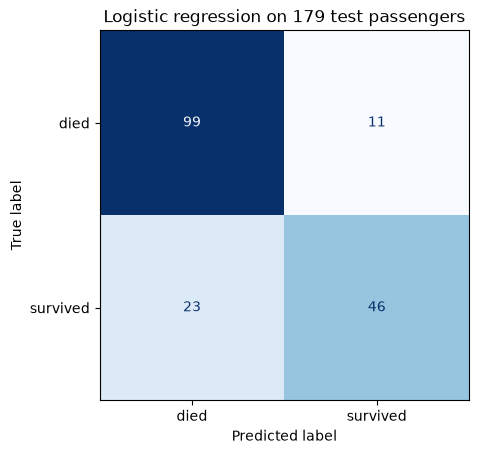

In [13]:
# Cell 3: Draw it

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["died", "survived"],
    cmap="Blues", colorbar=False,
)
plt.title("Logistic regression on 179 test passengers")
plt.savefig(output_dir / "confusion_matrix.png", bbox_inches="tight")
plt.show()

In [14]:
# Cell 4: Moving the 0.5 cut-off

chance = model.predict_proba(X_test_simple)[:, 1]
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (chance >= threshold).astype(int)
    print(f"threshold {threshold}: "
          f"precision {precision_score(y_test, pred):.2f}, "
          f"recall {recall_score(y_test, pred):.2f}, "
          f"predicted survivors {pred.sum()}")

threshold 0.3: precision 0.62, recall 0.81, predicted survivors 91
threshold 0.4: precision 0.65, recall 0.77, predicted survivors 82
threshold 0.5: precision 0.81, recall 0.67, predicted survivors 57
threshold 0.6: precision 0.86, recall 0.55, predicted survivors 44
threshold 0.7: precision 0.94, recall 0.46, predicted survivors 34


## Exercise 3 answers
- **Confusion matrix** `[[99 11] [23 46]]`: 99 deaths predicted correctly, 11 false alarms (predicted survived, died), 23 survivors missed (predicted died, survived), 46 survivors found.
- **Survived:** precision **0.81** (when it says "survived", it's right 81% of the time), recall **0.67** (it finds only 2 in 3 survivors).
- **Accuracy hides this:** 81% sounds good, but the model misses a third of the survivors.
- **The cut-off is a trade-off:** 0.3 gives recall 0.81 but precision 0.62; 0.7 gives precision 0.94 but recall 0.46. Choose it from the cost of each mistake.
